Exercice de dev pour l'entrainement d'un modèle
17/11/26

Étape 1 : Exploration des Données et Diagnostic Qualité

À l'aide de Pandas, 
- inspectez les types de variables = voir si catégrorielle (ou binaire) ou numérique -> df.dtypes
- quantifiez les valeurs manquantes et autres
  * vérifier que les valeurs sont non nulles df.info(): affiche le nombre de valeur non nulles
  * vérifier les valeurs aberrantes (il ne devrait pas y en avoir dans ce cas de test); 
  faire df.describe(include="all") pour avoir les min max etc.
  faire des tests sur les valeurs (vérifier que l'age et inf à 18 ou sup à X etc)
  * vérifier les valeurs manquantes
- analysez la distribution de la cible decision_octroi pour identifier l'éventuel déséquilibre de classes. 
- Veillez à ne jamais supprimer arbitrairement des lignes sans justification documentée.


Notes sur les colonnes 

id_dossier (DOS-10000)
montant_demande (16100.0)
duree_mois (48)
revenu_mensuel (3800.0)
taux_endettement (0.088)
age (27)
sexe (M)
statut_marital (celibataire)
nationalite (FR)
situation_logement (proprietaire)
anciennete_emploi_mois (31)
type_contrat (CDI)
epargne_globale (1820.0)
nb_credits_actifs (0)
incident_precedent (retard_leger)
score_credit (621.0)
decision_octroi (1)

In [28]:
###################################################
# Afficher les informations sur le dataset
# Inspectez les types de variables
################################################### 

from pathlib import Path

import pandas as pd

# Chargement direct et robuste du dataset synthétique
candidates = [
    Path('credit_risk_dataset.csv')
]
csv_path = next((p for p in candidates if p.exists()), Path('credit_risk_dataset.csv'))
df = pd.read_csv(csv_path)

print(f'Données chargées depuis : {csv_path.resolve()}')
print('Dimensions du dataset :', df.shape)

# Aperçu des premières lignes du dataset (5 par défaut)
print('---------------------- head du dataset (head) ----------------------')
df.head()


Données chargées depuis : C:\Workspace\Simplon\SocleApplicatif-module0\dev\credit_risk_dataset.csv
Dimensions du dataset : (1200, 17)
---------------------- head du dataset (head) ----------------------


,id_dossier,montant_demande,duree_mois,revenu_mensuel,taux_endettement,age,sexe,statut_marital,nationalite,situation_logement,anciennete_emploi_mois,type_contrat,epargne_globale,nb_credits_actifs,incident_precedent,score_credit,decision_octroi
0,DOS-10000,16100.0,48,3800.0,0.088,27,M,celibataire,FR,proprietaire,31,CDI,1820.0,0,retard_leger,621.0,1
1,DOS-10001,11100.0,12,3030.0,0.305,20,F,marie,FR,proprietaire,281,CDI,5930.0,0,aucun,693.8,1
2,DOS-10002,16100.0,12,3980.0,0.337,19,M,divorce,FR,locataire,38,CDI,980.0,2,aucun,677.8,1
3,DOS-10003,19900.0,72,5030.0,0.055,24,F,divorce,HORS_UE,proprietaire,48,CDD,20490.0,0,retard_leger,634.4,1
4,DOS-10004,15400.0,24,2920.0,0.220,32,F,divorce,FR,locataire,45,CDI,3570.0,1,retard_leger,634.2,1


In [29]:
# Informations détaillées sur le dataset
print('---------------------- informations détaillées (info) ----------------------')
# Indique les types et les non null par colonne
df.info()        

# Types de variables par colonne
print('---------------------- types de variables (dtypes) ----------------------')
print('Types de variables par colonne :', df.dtypes)

---------------------- informations détaillées (info) ----------------------
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_dossier              1200 non-null   str    
 1   montant_demande         1200 non-null   float64
 2   duree_mois              1200 non-null   int64  
 3   revenu_mensuel          1200 non-null   float64
 4   taux_endettement        1200 non-null   float64
 5   age                     1200 non-null   int64  
 6   sexe                    1200 non-null   str    
 7   statut_marital          1200 non-null   str    
 8   nationalite             1200 non-null   str    
 9   situation_logement      1200 non-null   str    
 10  anciennete_emploi_mois  1200 non-null   int64  
 11  type_contrat            1200 non-null   str    
 12  epargne_globale         1200 non-null   float64
 13  nb_credits_actifs       120

In [30]:
# Statistiques descriptives pour toutes les colonnes
# Résumé statistique de chaque variable numérique
# Permet de repérer des valeurs suspectes sans regarder les 1 200 lignes
# Affiche pour chaque colonne:
# - count: Nombre de valeurs non manquantes. Si c’est inférieur au nombre de lignes, il y a des manquants.
# - mean: moyenne
# - std: dispersion des valeurs autour de la moyenne
# - min / max: Valeurs extrêmes; c’est le plus utile pour détecter des erreurs.
# - 25% / 50% / 75%: Quartiles. La médiane (50 %) décrit le cas « typique »
# - unique: Nombre de valeurs uniques (utile pour les variables catégorielles)
# - top: Valeur la plus fréquente (utile pour les variables catégorielles)
# - freq: Fréquence de la valeur la plus fréquente (utile pour les variables catégorielles)
print('---------------------- statistiques descriptives (describe) ----------------------')
print(df.describe(include="all"))

# ages impossibles
print(f'Age inférieur à 18 : {(df["age"] < 18).sum()}')
print(f'Revenu mensuel inférieur ou égal à 0 : {(df["revenu_mensuel"] <= 0).sum()}')
print(f'Taux d\'endettement : {(df["taux_endettement"] > 1).sum()}')
print(f'Durée (mois) inférieure ou égale à 0 : {(df["duree_mois"] <= 0).sum()}')
print(f'Ancienneté emploi (mois) supérieur à l\'âge en mois : {(df["anciennete_emploi_mois"] > df["age"]*12).sum()}')

---------------------- statistiques descriptives (describe) ----------------------
       id_dossier  montant_demande   duree_mois  revenu_mensuel  \
count        1200      1200.000000  1200.000000     1200.000000   
unique       1200              NaN          NaN             NaN   
top     DOS-10000              NaN          NaN             NaN   
freq            1              NaN          NaN             NaN   
mean          NaN     15460.916667    40.510000     3264.175000   
std           NaN      8372.553207    17.985813     1147.409521   
min           NaN      1500.000000    12.000000     1200.000000   
25%           NaN      9200.000000    24.000000     2450.000000   
50%           NaN     15100.000000    36.000000     3260.000000   
75%           NaN     21100.000000    48.000000     4012.500000   
max           NaN     43700.000000    84.000000     7820.000000   

        taux_endettement          age  sexe statut_marital nationalite  \
count        1200.000000  1200.000000 

In [31]:
# vérifier les valeurs manquantes
df.isna().sum()

id_dossier                0
montant_demande           0
duree_mois                0
revenu_mensuel            0
taux_endettement          0
age                       0
sexe                      0
statut_marital            0
nationalite               0
situation_logement        0
anciennete_emploi_mois    0
type_contrat              0
epargne_globale           0
nb_credits_actifs         0
incident_precedent        0
score_credit              0
decision_octroi           0
dtype: int64

In [32]:
# Analyser la cible decision_octroi
print('Valeurs de la cible decision_octroi :')
print(df["decision_octroi"].value_counts(dropna=False))
# ==> il y a déséquilibre de classe
# Cela aura des conséquences pour la suite : choix de métriques (F1, AUC-PR, rappel plutôt que l’accuracy), stratification du split, éventuel rééquilibrage (class_weight, SMOTE).

df["decision_octroi"].value_counts(normalize=True).round(3)

Valeurs de la cible decision_octroi :
decision_octroi
0    748
1    452
Name: count, dtype: int64


decision_octroi
0    0.623
1    0.377
Name: proportion, dtype: float64

Analyse:

Type relevés:

1) catégorielles (str)
sexe, statut_marital, nationalite, situation_logement, type_contrat, incident_precedent

2) numériques
montant_demande, duree_mois, revenu_mensuel, taux_endettement, age, anciennete_emploi_mois, epargne_globale, nb_credits_actifs

3) Décision de suppression de certaines valeurs avec justification
- id_dossier: identifiant (à ne pas utiliser comme variable).
- decision_octroi: à ne pas utiliser comme valeur, c'est l'output
- score_credit: à ne pas utiliser comme valeur, c'est l'output


Étape 2 : Feature Engineering Raisonné
Les modèles linéaires et arborescents gagnent considérablement en précision lorsque l'on explicite des ratios financiers clés. 
Vous êtes invités à concevoir au moins deux variables dérivées métiers, par exemple :
●	Ratio Reste à Vivre : Revenu mensuel diminué de la charge de crédit estimée.
●	Ratio Épargne / Emprunt : Épargne globale rapportée au montant total sollicité.


In [ ]:

## transforamtion de données
# mettre dans le df les nouvelles valeurs et supprimer celles qui ont servie à faire le calcul

# Mensualité du nouveau crédit (remboursement linéaire, sans intérêts)
df["mensualite_estimee"] = df["montant_demande"] / df["duree_mois"]

# Charge des crédits déjà en cours
df["charge_existante"] = df["taux_endettement"] * df["revenu_mensuel"]

# 1. Reste à vivre (en €)
df["reste_a_vivre"] = (df["revenu_mensuel"]
                       - df["charge_existante"]
                       - df["mensualite_estimee"])


# 2. Reste à vivre en proportion du revenu
df["ratio_reste_a_vivre"] = df["reste_a_vivre"] / df["revenu_mensuel"]

# 3. Ratio épargne / emprunt
df["ratio_epargne_emprunt"] = df["epargne_globale"] / df["montant_demande"]

# 4. Taux d'endettement après octroi
#df["taux_endettement_projete"] = ((df["charge_existante"] + df["mensualite_estimee"]) / df["revenu_mensuel"])

# 5. Montant demandé rapporté au revenu annuel
#df["montant_sur_revenu_annuel"] = df["montant_demande"] / (df["revenu_mensuel"] * 12)

# 6. Indicateur d'incohérence ancienneté / âge (1 = incohérent)
#df["anciennete_incoherente"] = (df["anciennete_emploi_mois"] > (df["age"] - 16) * 12).astype(int)

Étape 3 : Construction du Pipeline Scikit-Learn Étanche
Pour éviter toute fuite d'information (Data Leakage) entre le train et le test, l'intégralité du prétraitement doit être encapsulée dans un ColumnTransformer standardisé :
●	Branche numérique : Imputation par la médiane (SimpleImputer) suivie d'une standardisation (StandardScaler).
●	Branche catégorielle : Imputation par constante 'INCONNU' suivie d'un encodage OneHot (OneHotEncoder avec handle_unknown='ignore').
●	Pipeline unifié : Assemblage du ColumnTransformer et de l'estimateur dans un objet Pipeline unique.

In [34]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_features = ["montant_demande", "duree_mois", "revenu_mensuel", "taux_endettement", "age", "anciennete_emploi_mois", "epargne_globale", "nb_credits_actifs"]
cat_features = ["sexe", "statut_marital", "nationalite", "situation_logement", "type_contrat", "incident_precedent"]

num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Créer une colonne « inconnu » pour le reste des données
cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="INCONNU")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])


preprocessor = ColumnTransformer(transformers=[
    ("num", num_transformer, num_features),
    ("cat", cat_transformer, cat_features)
])

# Pipeline complet : Prétraitement étanche + Modèle unifié
full_pipeline_RandomForest = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

# Sauvegarder le pipeline complet pour une utilisation ultérieure
joblib.dump(full_pipeline_RandomForest, "full_pipeline.pkl")
print("Pipeline sauvegardé sous 'full_pipeline.pkl'")


Pipeline sauvegardé sous 'full_pipeline.pkl'


Étape 4 : Validation Croisée K-Fold Stratifiée

Il est formellement interdit d'ajuster vos hyperparamètres sur le jeu de test final. 
Vous devez configurer une validation croisée à 5 plis stratifiés (StratifiedKFold) sur vos données d'entraînement. 
Vos scores de comparaison intermédiaires doivent obligatoirement être présentés sous forme moyenne +/- écart-type.


In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

# 1) On met de côté un jeu de test final, jamais touché pendant le tuning

# toutes les colonnes sauf les cibles et la colonne non pertinente "id_dossier"
X = df.drop(columns=["decision_octroi", "score_credit", "id_dossier"])
 # uniquement la cible (valeur binaire pour le classifieur)
y = df["decision_octroi"]               

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# 2) Validation croisée uniquement sur le jeu d'entraînement
# Configuration des 5 plis stratifiés avec mélange aléatoire contrôlé
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(full_pipeline_RandomForest, X_train, y_train, cv=cv, scoring="f1")
print(f"F1 CV Random Forest : {scores.mean():.3f} ± {scores.std():.3f}")

# 3) Évaluation finale, une seule fois, sur le jeu de test
# On entraîne le pipeline sur tout le jeu d’entraînement
full_pipeline_RandomForest.fit(X_train, y_train)

# Le pipeline applique le preprocessor déjà ajusté à X_test (simple transform, sans réajustement).
# Le modèle prédit sur X_test, puis la prédiction est comparée à y_test.
# Le résultat est affiché.
print(f"F1 test Random Forest : {f1_score(full_pipeline_RandomForest.predict(X_test), y_test):.3f}")
# predict proba 
print(f"Predict proba test Random Forest : {full_pipeline_RandomForest.predict_proba(X_test)[:, 1]}")



F1 CV Random Forest : 0.706 ± 0.021
F1 test Random Forest : 0.747
Predict proba test Random Forest : [0.19 0.71 0.48 0.53 0.04 0.33 0.73 0.26 0.08 0.63 0.22 0.84 0.04 0.12
 0.24 0.79 0.35 0.51 0.81 0.41 0.57 0.14 0.26 0.5  0.55 0.21 0.04 0.18
 0.56 0.18 0.1  0.4  0.6  0.26 0.31 0.75 0.03 0.84 0.64 0.18 0.58 0.05
 0.75 0.1  0.19 0.87 0.25 0.03 0.08 0.55 0.05 0.06 0.22 0.34 0.05 0.71
 0.19 0.04 0.38 0.72 0.22 0.67 0.1  0.29 0.72 0.67 0.2  0.16 0.04 0.18
 0.9  0.85 0.69 0.28 0.65 0.43 0.67 0.08 0.25 0.5  0.1  0.21 0.15 0.39
 0.4  0.85 0.64 0.15 0.15 0.37 0.69 0.44 0.06 0.21 0.35 0.66 0.09 0.04
 0.19 0.04 0.24 0.05 0.07 0.54 0.07 0.9  0.13 0.58 0.19 0.17 0.85 0.35
 0.39 0.8  0.06 0.57 0.53 0.01 0.61 0.2  0.05 0.16 0.87 0.14 0.69 0.35
 0.5  0.86 0.83 0.01 0.75 0.21 0.61 0.69 0.26 0.28 0.28 0.77 0.15 0.52
 0.1  0.53 0.08 0.05 0.17 0.68 0.11 0.15 0.75 0.03 0.45 0.71 0.08 0.26
 0.89 0.63 0.55 0.17 0.82 0.49 0.67 0.07 0.17 0.74 0.06 0.47 0.21 0.51
 0.35 0.01 0.1  0.87 0.25 0.07 0.15 0.63 0.83 0

In [ ]:
# Faire le test avec d'autres modèles

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

#### Logistic Regression: Modèle le plus simple pour la classification binaire
# bien pour pas beaucoup de données 
# !! modèle linéraire
# données simples (ex: ventes etc)
full_pipeline_LogisticRegression = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

scoresLogisticRegression = cross_val_score(full_pipeline_LogisticRegression, X_train, y_train, cv=cv, scoring="f1")
print(f"F1 CV Logistic Regression : {scoresLogisticRegression.mean():.3f} ± {scoresLogisticRegression.std():.3f}")

full_pipeline_LogisticRegression.fit(X_train, y_train)

print(f"F1 test Logistic Regression : {f1_score(full_pipeline_LogisticRegression.predict(X_test), y_test):.3f}")

#### Gradient boosting
full_pipeline_GradientBoosting = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

scoresGradientBoosting = cross_val_score(full_pipeline_GradientBoosting, X_train, y_train, cv=cv, scoring="f1")
print(f"F1 CV Gradient boosting : {scoresGradientBoosting.mean():.3f} ± {scoresGradientBoosting.std():.3f}")

full_pipeline_GradientBoosting.fit(X_train, y_train)
print(f"F1 test Gradient boosting : {f1_score(full_pipeline_GradientBoosting.predict(X_test), y_test):.3f}")




F1 CV Logistic Regression : 0.743 ± 0.025
F1 test Logistic Regression : 0.775
F1 CV Gradient boosting : 0.744 ± 0.020
F1 test Gradient boosting : 0.730


Étape 5 : Optimisation Bayésienne avec Optuna

Mettez en place une étude Optuna (Study) pour calibrer automatiquement les hyperparamètres clés de vos modèles 
(ex. nombre d'arbres n_estimators, profondeur max_depth, critère de division). 

Comparez au moins deux familles d'algorithmes (ex. Forêts Aléatoires vs Gradient Boosting / XGBoost).

In [ ]:
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier


def objective_rf(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 20),
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"]),
    }
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(**params, random_state=42, n_jobs=-1)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    trial.set_user_attr("std", scores.std())   # pour rapporter moyenne ± écart-type
    return scores.mean()



def objective_xgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
    }
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(**params, random_state=42, eval_metric="logloss")),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    trial.set_user_attr("std", scores.std())
    return scores.mean()



# Une étude par famille, même seed pour la reproductibilité
study_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_rf.optimize(objective_rf, n_trials=30)

study_xgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_xgb.optimize(objective_xgb, n_trials=30)

# Comparaison (moyenne ± écart-type du meilleur essai)
for nom, study in [("RandomForest", study_rf), ("XGBoost", study_xgb)]:
    print(f"{nom:13s} F1 CV = {study.best_value:.3f} ± {study.best_trial.user_attrs['std']:.3f}")
    print("  meilleurs paramètres :", study.best_params)

[I 2026-11-19 15:57:21,191] A new study created in memory with name: no-name-a54dd3e0-2f55-4953-99f9-befd42fcc0d3
[I 2026-11-19 15:57:24,599] Trial 0 finished with value: 0.7249963326699302 and parameters: {'n_estimators': 250, 'max_depth': 20, 'min_samples_split': 15, 'criterion': 'gini'}. Best is trial 0 with value: 0.7249963326699302.
[I 2026-11-19 15:57:26,910] Trial 1 finished with value: 0.7244808350690704 and parameters: {'n_estimators': 123, 'max_depth': 18, 'min_samples_split': 13, 'criterion': 'log_loss'}. Best is trial 0 with value: 0.7249963326699302.
[I 2026-11-19 15:57:31,914] Trial 2 finished with value: 0.7139208550093095 and parameters: {'n_estimators': 433, 'max_depth': 6, 'min_samples_split': 5, 'criterion': 'log_loss'}. Best is trial 0 with value: 0.7249963326699302.
[I 2026-11-19 15:57:35,563] Trial 3 finished with value: 0.725910338043725 and parameters: {'n_estimators': 273, 'max_depth': 8, 'min_samples_split': 13, 'criterion': 'log_loss'}. Best is trial 3 with v

RandomForest  F1 CV = 0.732 ± 0.019
  meilleurs paramètres : {'n_estimators': 379, 'max_depth': 13, 'min_samples_split': 20, 'criterion': 'log_loss'}
XGBoost       F1 CV = 0.756 ± 0.024
  meilleurs paramètres : {'n_estimators': 119, 'max_depth': 3, 'learning_rate': 0.07606108100491758, 'subsample': 0.8344249884279323, 'colsample_bytree': 0.6355387735805572}


In [21]:
from sklearn.metrics import f1_score

final_model_rf = RandomForestClassifier(**study_rf.best_params, random_state=42, n_jobs=-1)
final_pipeline_rf = Pipeline([("preprocessor", preprocessor), ("model", final_model_rf)])
final_pipeline_rf.fit(X_train, y_train)
y_pred = final_pipeline_rf.predict(X_test)
print(f"F1 test : {f1_score(y_test, y_pred):.3f}")

final_model_xgb = XGBClassifier(**study_xgb.best_params, random_state=42, eval_metric="logloss")
final_pipeline_xgb = Pipeline([("preprocessor", preprocessor), ("model", final_model_xgb)])
final_pipeline_xgb.fit(X_train, y_train)
y_pred = final_pipeline_xgb.predict(X_test)
print(f"F1 test : {f1_score(y_test, y_pred):.3f}")


F1 test : 0.757
F1 test : 0.752


Deux artefacts de modèles sérialisés au format joblib prêts à l'inférence (best_regressor_pipeline.joblib et best_classifier_pipeline.joblib).

In [23]:
joblib.dump(final_pipeline_rf, "best_regressor_pipeline_rf.joblib")
joblib.dump(final_pipeline_xgb, "best_regressor_pipeline_xgb.joblib")

['best_regressor_pipeline_xgb.joblib']

Retester l'ouverture

In [37]:
rf = joblib.load("best_regressor_pipeline_rf.joblib")
xgb = joblib.load("best_regressor_pipeline_xgb.joblib")

print(rf.predict(X_test.head()), y_test[:5])
print(xgb.predict(X_test.head()), y_test[:5])

[0 1 0 1 0] 1115    0
730     0
572     0
886     1
449     0
Name: decision_octroi, dtype: int64
[0 1 0 1 0] 1115    0
730     0
572     0
886     1
449     0
Name: decision_octroi, dtype: int64


Présentation des résultats

Matrices de confusion

TODO: afficher le Roc AUC

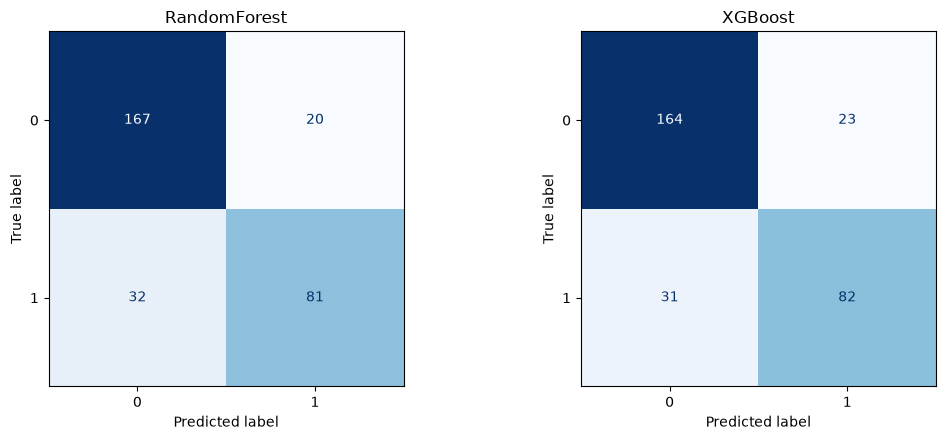

In [25]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

pipe_rf = Pipeline([("preprocessor", preprocessor),
                    ("model", RandomForestClassifier(**study_rf.best_params, random_state=42, n_jobs=-1))])
pipe_xgb = Pipeline([("preprocessor", preprocessor),
                     ("model", XGBClassifier(**study_xgb.best_params, random_state=42, eval_metric="logloss"))])

pipe_rf.fit(X_train, y_train)
pipe_xgb.fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (nom, pipe) in zip(axes, [("RandomForest", pipe_rf), ("XGBoost", pipe_xgb)]):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_test, y_test, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(nom)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

Courbes de convergence Optuna

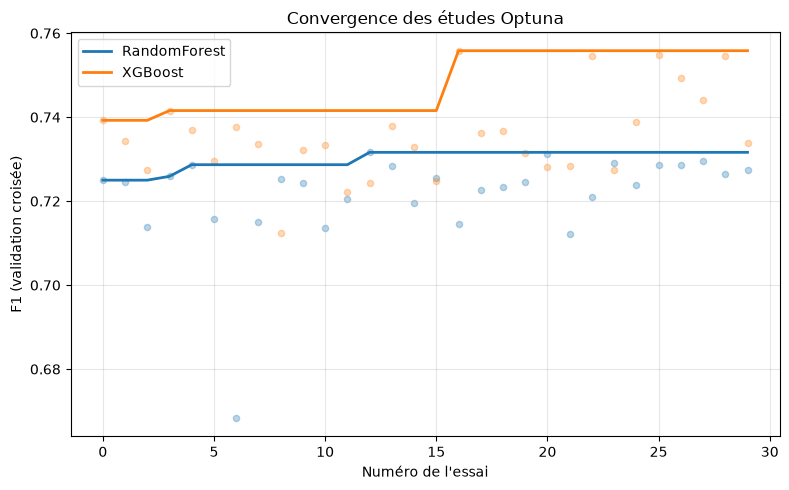

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))

for nom, study in [("RandomForest", study_rf), ("XGBoost", study_xgb)]:
    df = study.trials_dataframe()
    ax.scatter(df["number"], df["value"], alpha=0.3, s=20)          # score de chaque essai
    ax.plot(df["number"], df["value"].cummax(), label=nom, lw=2)   # meilleur score cumulé

ax.set_xlabel("Numéro de l'essai")
ax.set_ylabel("F1 (validation croisée)")
ax.set_title("Convergence des études Optuna")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("optuna_convergence.png", dpi=150)
plt.show()

A quel moment il fallait faire l'entrainement sur les modèles simple Logistique régression?

